# 🔍 EfficientNet-B4 — Error Analysis, Metrics & XAI

This notebook:
1. Loads the **fine-tuned EfficientNet-B4** checkpoint from Google Drive
2. Runs inference on the **held-out test set** (same split as training notebook)
3. Performs **error analysis** — wrong predictions broken down by generator model
4. Reports **Recall, F1, ROC-AUC** and full classification metrics
5. Visualises model decisions with **Grad-CAM** (XAI)
6. Evaluates on a **new unseen dataset** (different generator models not seen during training)

> Set runtime to **GPU → T4** before running.

## 1. Mount Drive & Extract Original Dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os, zipfile

# ── CHANGE THESE PATHS ────────────────────────────────────────────────────────
ZIP_PATH        = '/content/drive/MyDrive/Image Processing Project/openfake_subset.zip'
EXTRACT_TO      = '/content/dataset'
MODEL_PATH      = '/content/drive/MyDrive/EfficientModel/efficientnet_deepfake_binary.pth'

# # New unseen dataset (different generator models — not seen during training)
# NEW_ZIP_PATH    = '/content/drive/MyDrive/EfficientModel/ood_test'   # ← update
# NEW_EXTRACT_TO  = '/content/new_dataset'
# ─────────────────────────────────────────────────────────────────────────────

def extract_zip(zip_path, extract_to):
    if not os.path.exists(extract_to):
        print(f'Extracting {os.path.basename(zip_path)}...')
        with zipfile.ZipFile(zip_path, 'r') as zf:
            zf.extractall(extract_to)
        print('Done.')
    else:
        print(f'Already extracted: {extract_to}')
    entries = os.listdir(extract_to)
    root = (
        os.path.join(extract_to, entries[0])
        if len(entries) == 1 and os.path.isdir(os.path.join(extract_to, entries[0]))
        else extract_to
    )
    return root

DATA_ROOT = extract_zip(ZIP_PATH, EXTRACT_TO)
CSV_PATH   = os.path.join(DATA_ROOT, 'metadata.csv')
IMAGES_DIR = os.path.join(DATA_ROOT, 'images')
print(f'Images dir  : {IMAGES_DIR}  ({len(os.listdir(IMAGES_DIR)):,} files)')

Extracting openfake_subset.zip...
Done.
Images dir  : /content/dataset/images  (9,000 files)


## 2. Install & Import

In [ ]:
!pip install timm grad-cam --quiet

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 85.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

import timm
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay,
    recall_score, f1_score, precision_score
)
from tqdm.notebook import tqdm
import warnings
warnings.filterwarnings('ignore')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device : {DEVICE}')
if DEVICE.type == 'cuda':
    print(f'GPU    : {torch.cuda.get_device_name(0)}')

Device : cuda
GPU    : Tesla T4


## 3. Configuration

In [ ]:
CFG = {
    'model_name'  : 'efficientnet_b4',
    'num_classes' : 2,
    'img_size'    : 256,
    'train_frac'  : 0.8,
    'val_frac'    : 0.1,
    'batch_size'  : 32,
    'num_workers' : 2,
    'seed'        : 42,
}

CLASS_NAMES = ['real', 'fake']

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]
SIZE = CFG['img_size']

torch.manual_seed(CFG['seed'])
np.random.seed(CFG['seed'])

# Inference-only transforms (no augmentation)
test_transforms = transforms.Compose([
    transforms.Resize((SIZE + 32, SIZE + 32)),
    transforms.CenterCrop(SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

def denormalise(tensor):
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std  = torch.tensor(IMAGENET_STD ).view(3, 1, 1)
    return (tensor * std + mean).clamp(0, 1)

print('Config ready.')

Config ready.


## 4. Load CSV & Build Binary Labels

In [ ]:
try:
    df = pd.read_csv(CSV_PATH, sep='\t')
    assert len(df.columns) > 1
except Exception:
    df = pd.read_csv(CSV_PATH, sep=',')

df['filename']      = df['image_path'].apply(os.path.basename)
df['resolved_path'] = df['filename'].apply(lambda f: os.path.join(IMAGES_DIR, f))
df['binary_label']  = df['label'].apply(
    lambda x: 0 if str(x).strip().lower() == 'real' else 1
)

exists_mask = df['resolved_path'].apply(os.path.exists)
if (~exists_mask).sum() > 0:
    print(f'Warning: {(~exists_mask).sum()} missing images dropped.')
df = df[exists_mask].reset_index(drop=True)

print(f'Total: {len(df):,}  |  real={( df.binary_label==0).sum():,}  fake={(df.binary_label==1).sum():,}')
print(f'Generator models in dataset: {df["model"].unique().tolist()}')

Total: 8,989  |  real=3,000  fake=5,989
Generator models in dataset: ['real', 'sd-2.1', 'sdxl', 'sd-1.5', 'sd-1.5-dreamshaper', 'sdxl-juggernaut', 'sdxl-epic-realism', 'sdxl-realvis-v5', 'midjourney-6', 'sdxl-touchofrealism', 'sd-3.5', 'midjourney-7', 'sd-1.5-epicdream']


## 5. Reproduce the Same Test Split

Using identical seed and fractions as the training notebook to ensure the test set is untouched.

In [ ]:
def split_df(dataframe, splits=(0.8, 0.1, 0.1), seed=42):
    dataframe = dataframe.sample(frac=1, random_state=seed).reset_index(drop=True)
    n = len(dataframe)
    n_train = int(n * splits[0])
    n_val   = int(n * splits[1])
    return {
        'train': dataframe.iloc[:n_train],
        'val'  : dataframe.iloc[n_train:n_train + n_val],
        'test' : dataframe.iloc[n_train + n_val:]
    }

val_frac   = CFG['val_frac']
train_frac = CFG['train_frac']
test_frac  = 1 - train_frac - val_frac

real_splits = split_df(df[df.binary_label==0].copy(), (train_frac, val_frac, test_frac), CFG['seed'])
fake_splits = split_df(df[df.binary_label==1].copy(), (train_frac, val_frac, test_frac), CFG['seed'])

df_test = pd.concat([real_splits['test'], fake_splits['test']]).reset_index(drop=True)
df_test = df_test.sample(frac=1, random_state=CFG['seed']).reset_index(drop=True)

r = (df_test.binary_label == 0).sum()
f = (df_test.binary_label == 1).sum()
print(f'Test set: {len(df_test):,} total  |  real={r:,}  fake={f:,}')
print(f'Generator models in test set: {df_test["model"].unique().tolist()}')

Test set: 900 total  |  real=300  fake=600
Generator models in test set: ['real', 'midjourney-6', 'sdxl-touchofrealism', 'sdxl-realvis-v5', 'sd-1.5-dreamshaper', 'sd-2.1', 'sd-1.5', 'sdxl', 'sdxl-juggernaut', 'sd-3.5', 'sdxl-epic-realism', 'sd-1.5-epicdream', 'midjourney-7']


## 6. Dataset Class

In [ ]:
class DeepFakeDataset(Dataset):
    """Works for both the original dataset (has 'model' column) and new dataset."""
    def __init__(self, dataframe, transform=None, has_model_col=True):
        self.df           = dataframe.reset_index(drop=True)
        self.transform    = transform
        self.has_model_col = has_model_col

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row   = self.df.iloc[idx]
        img   = Image.open(row['resolved_path']).convert('RGB')
        label = int(row['binary_label'])
        if self.transform:
            img = self.transform(img)
        model_name = row['model'] if self.has_model_col else 'unknown'
        return img, label, model_name, str(row['resolved_path'])


def make_loader(df, transform, has_model_col=True, batch_size=32, num_workers=2):
    ds = DeepFakeDataset(df, transform, has_model_col)
    return DataLoader(ds, batch_size=batch_size, shuffle=False,
                      num_workers=num_workers, pin_memory=True)

test_loader = make_loader(df_test, test_transforms, has_model_col=True,
                          batch_size=CFG['batch_size'], num_workers=CFG['num_workers'])
print('DataLoader ready.')

DataLoader ready.


## 7. Load Fine-Tuned Model from Drive

In [ ]:
def load_model(checkpoint_path, cfg, device):
    model = timm.create_model(
        cfg['model_name'],
        pretrained=False,          # weights come from checkpoint
        num_classes=cfg['num_classes']
    )
    state = torch.load(checkpoint_path, map_location=device)
    model.load_state_dict(state)
    model.to(device)
    model.eval()
    total = sum(p.numel() for p in model.parameters())
    print(f'✅ Loaded  : {checkpoint_path}')
    print(f'   Model   : {cfg["model_name"]}  |  params: {total:,}')
    return model

model = load_model(MODEL_PATH, CFG, DEVICE)

✅ Loaded  : /content/drive/MyDrive/EfficientModel/efficientnet_deepfake_binary.pth
   Model   : efficientnet_b4  |  params: 17,552,202


## 8. Run Inference

In [ ]:
def run_inference(loader, model, device):
    """Returns arrays of predictions, true labels, probabilities, generator names, paths."""
    all_preds, all_labels, all_probs = [], [], []
    all_models, all_paths = [], []

    with torch.no_grad():
        for images, labels, model_names, paths in tqdm(loader, desc='Inference'):
            images  = images.to(device)
            logits  = model(images)
            probs   = torch.softmax(logits, dim=1)[:, 1].cpu().numpy()
            preds   = logits.argmax(dim=1).cpu().numpy()
            all_preds .extend(preds)
            all_labels.extend(labels.numpy())
            all_probs .extend(probs)
            all_models.extend(model_names)
            all_paths .extend(paths)

    return (np.array(all_preds), np.array(all_labels),
            np.array(all_probs), np.array(all_models), np.array(all_paths))

preds, labels, probs, gen_models, img_paths = run_inference(test_loader, model, DEVICE)
print(f'Inference done on {len(preds):,} images.')

Inference:   0%|          | 0/29 [00:00<?, ?it/s]

Inference done on 900 images.


## 9. Overall Metrics — Accuracy, Recall, F1, ROC-AUC

In [ ]:
acc     = np.mean(preds == labels)
auc     = roc_auc_score(labels, probs)
recall  = recall_score(labels, preds, average='macro')
f1      = f1_score(labels, preds, average='macro')
prec    = precision_score(labels, preds, average='macro')

print('=' * 45)
print(f'  Overall Accuracy  : {acc:.4f}  ({acc*100:.2f}%)')
print(f'  ROC-AUC           : {auc:.4f}')
print(f'  Macro Precision   : {prec:.4f}')
print(f'  Macro Recall      : {recall:.4f}')
print(f'  Macro F1-Score    : {f1:.4f}')
print('=' * 45)
print()
print('Per-class Report:')
print(classification_report(labels, preds, target_names=CLASS_NAMES, digits=4))

  Overall Accuracy  : 0.8878  (88.78%)
  ROC-AUC           : 0.9512
  Macro Precision   : 0.8718
  Macro Recall      : 0.8783
  Macro F1-Score    : 0.8749

Per-class Report:
              precision    recall  f1-score   support

        real     0.8199    0.8500    0.8347       300
        fake     0.9236    0.9067    0.9151       600

    accuracy                         0.8878       900
   macro avg     0.8718    0.8783    0.8749       900
weighted avg     0.8890    0.8878    0.8883       900



## 10. Confusion Matrix & ROC Curve

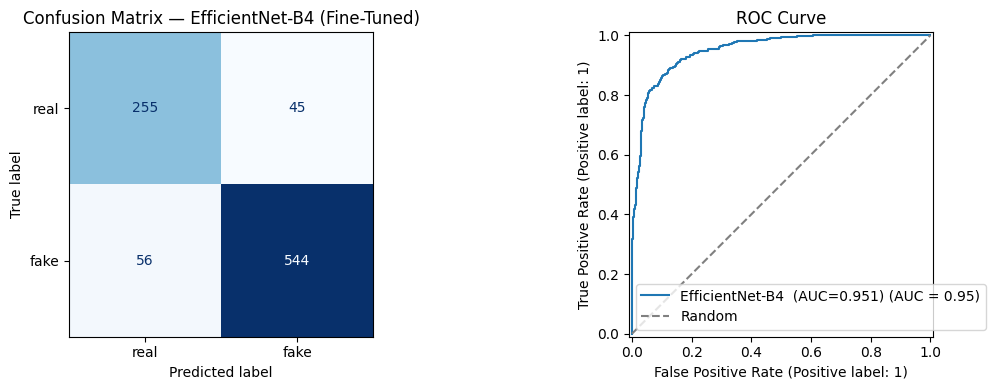

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

cm = confusion_matrix(labels, preds)
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(
    ax=ax1, cmap='Blues', colorbar=False
)
ax1.set_title('Confusion Matrix — EfficientNet-B4 (Fine-Tuned)')

RocCurveDisplay.from_predictions(
    labels, probs,
    name=f'EfficientNet-B4  (AUC={auc:.3f})',
    ax=ax2
)
ax2.plot([0, 1], [0, 1], '--', color='gray', label='Random')
ax2.set_title('ROC Curve')
ax2.legend()

plt.tight_layout()
plt.show()

## 11. Per-Generator-Model Metrics

Breaks down Accuracy, Recall, and F1 for each generator model present in the test set.

In [ ]:
results_df = pd.DataFrame({
    'pred'      : preds,
    'label'     : labels,
    'prob'      : probs,
    'generator' : gen_models,
    'path'      : img_paths,
})

# ── Normalise generator names → group all variants of the same model ──────────
# e.g. 'stable_diffusion_v1', 'stable-diffusion-xl' → 'stable_diffusion'
#      'midjourney_v5', 'midjourney-v6'              → 'midjourney'
def normalise_gen(name):
    n = str(name).lower().replace('-', '_').replace(' ', '_')
    if 'stable' in n or 'sd' in n:
        return 'stable_diffusion'
    if 'midjourney' in n or 'mj' == n:
        return 'midjourney'
    if name == 'real' or name == '0':
        return '__real__'      # will be excluded below
    return n                   # keep any other generator as-is

results_df['generator_group'] = results_df['generator'].apply(normalise_gen)

# Shared real pool: ALL real images in the test set (label == 0)
real_pool = results_df[results_df['label'] == 0].copy()
print(f'Real image pool : {len(real_pool):,}')

# Fake generators only (exclude the __real__ bucket)
fake_df    = results_df[
    (results_df['label'] == 1) & (results_df['generator_group'] != '__real__')
].copy()
generators = sorted(fake_df['generator_group'].unique())
print(f'Fake generators : {generators}')

gen_stats = []
for gen in generators:
    # All fakes from this generator
    sub     = fake_df[fake_df['generator_group'] == gen]
    n_fake  = len(sub)
    n_wrong = (sub['pred'].values != 1).sum()   # predicted real instead of fake

    # Combine with real pool → gives us both classes for all metrics
    combined  = pd.concat([sub, real_pool])
    yc_true   = combined['label'].values
    yc_pred   = combined['pred'].values
    yc_prob   = combined['prob'].values          # P(fake)

    acc  = np.mean(sub['pred'].values == 1)      # fake detection rate
    auc  = roc_auc_score(yc_true, yc_prob)
    rec  = recall_score(yc_true, yc_pred,    average='macro', zero_division=0)
    f1   = f1_score(yc_true, yc_pred,        average='macro', zero_division=0)
    prec = precision_score(yc_true, yc_pred, average='macro', zero_division=0)

    gen_stats.append({
        'Generator'        : gen,
        'N_fake'           : n_fake,
        'N_real'           : len(real_pool),
        'N_wrong (missed)' : n_wrong,
        'Detection_Rate%'  : round(100 * acc,  2),
        'Error_%'          : round(100 * n_wrong / n_fake, 2),
        'ROC-AUC'          : round(auc,  4),
        'Recall (macro)'   : round(rec,  4),
        'F1 (macro)'       : round(f1,   4),
        'Precision (macro)': round(prec, 4),
    })

stats_df = pd.DataFrame(gen_stats).set_index('Generator')

print('\n── Per-Generator Binary Evaluation (generator fakes vs all real) ──')
print('  Detection_Rate% = % of that generator\'s fakes correctly predicted as fake')
print('  Recall/F1/Precision/AUC computed on [generator fakes + all real images]\n')
display(stats_df)

Real image pool : 300
Fake generators : ['midjourney', 'stable_diffusion']

── Per-Generator Binary Evaluation (generator fakes vs all real) ──
  Detection_Rate% = % of that generator's fakes correctly predicted as fake
  Recall/F1/Precision/AUC computed on [generator fakes + all real images]



,N_fake,N_real,N_wrong (missed),Detection_Rate%,Error_%,ROC-AUC,Recall (macro),F1 (macro),Precision (macro)
Generator,,,,,,,,,
midjourney,304,300,6,98.03,1.97,0.9788,0.9151,0.9151,0.9229
stable_diffusion,296,300,50,83.11,16.89,0.9229,0.8405,0.8406,0.8407


## 12. Error Analysis — Misclassified Images per Generator

For each generator model, display a grid of wrongly classified samples with their true label, predicted label, and confidence.

In [ ]:
wrong_df = results_df[results_df['pred'] != results_df['label']].copy()
print(f'Total misclassified: {len(wrong_df):,} / {len(results_df):,}  '
      f'({100*len(wrong_df)/len(results_df):.2f}%)')
print()
print('Misclassifications per generator:')
display(wrong_df['generator'].value_counts().rename('n_errors').to_frame())

Total misclassified: 101 / 900  (11.22%)

Misclassifications per generator:


,n_errors
generator,
stable_diffusion,50
real,45
midjourney,6


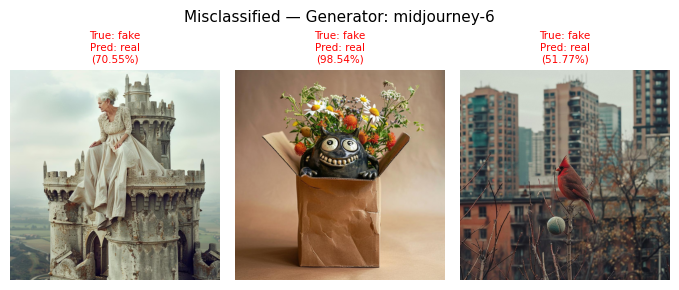

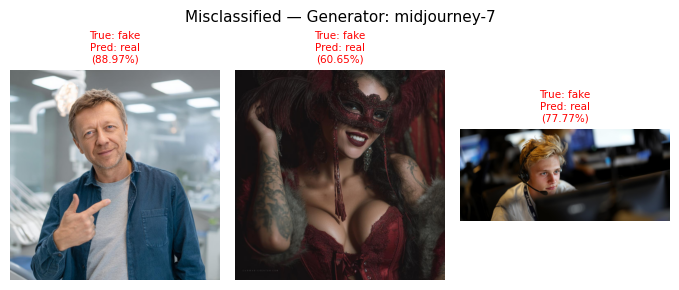

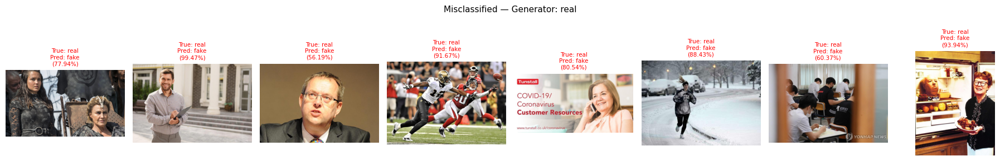

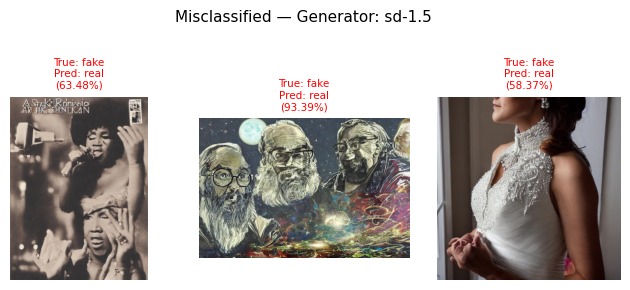

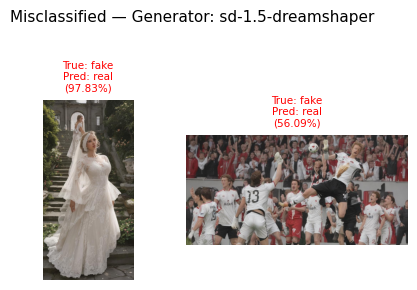

...

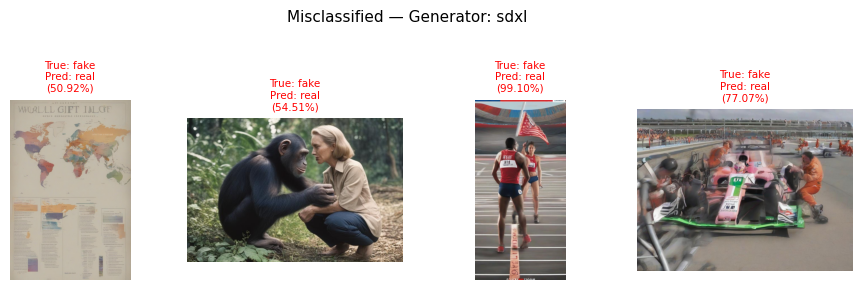

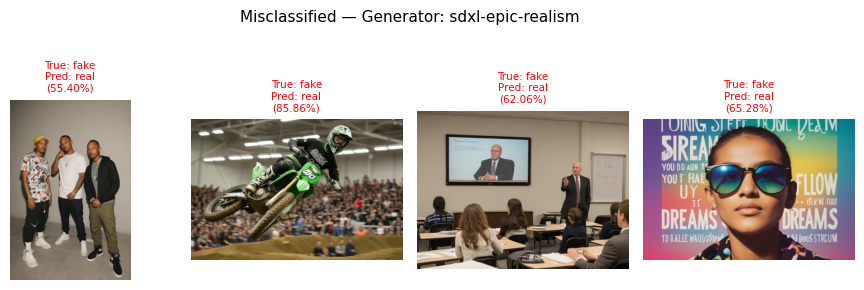

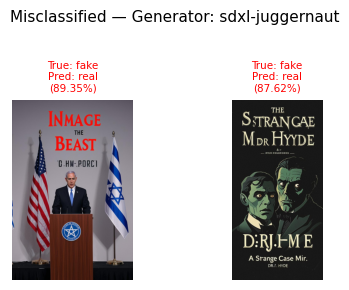

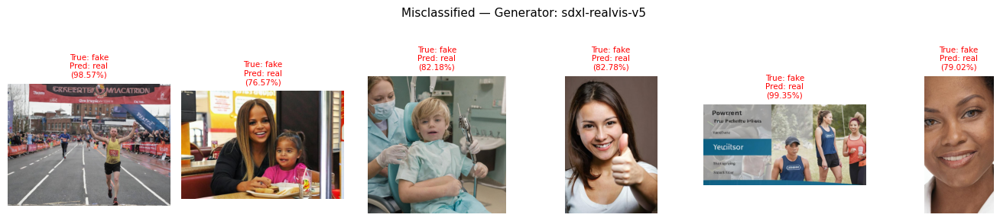

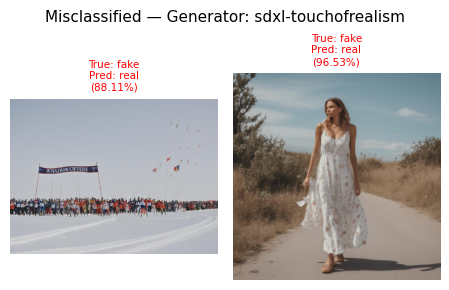

In [ ]:
def show_errors(wrong_df, generator, n_show=8, figsize_per=(2.3, 2.8)):
    """Display a grid of misclassified images for a given generator model."""
    sub = wrong_df[wrong_df['generator'] == generator].head(n_show)
    if sub.empty:
        print(f'No errors for generator: {generator}')
        return

    n = len(sub)
    fig, axes = plt.subplots(1, n, figsize=(figsize_per[0] * n, figsize_per[1]))
    if n == 1:
        axes = [axes]

    for ax, (_, row) in zip(axes, sub.iterrows()):
        img = Image.open(row['path']).convert('RGB')
        ax.imshow(img)
        true_lbl = CLASS_NAMES[int(row['label'])]
        pred_lbl = CLASS_NAMES[int(row['pred'])]
        conf     = row['prob'] if row['pred'] == 1 else 1 - row['prob']
        ax.set_title(
            f'True: {true_lbl}\nPred: {pred_lbl}\n({conf:.2%})',
            fontsize=7.5,
            color='red'
        )
        ax.axis('off')

    plt.suptitle(f'Misclassified — Generator: {generator}', fontsize=11, y=1.02)
    plt.tight_layout()
    plt.show()


# Show errors for every generator that has at least one mistake
for gen in sorted(wrong_df['generator'].unique()):
    show_errors(wrong_df, gen, n_show=8)

## 13. XAI — Grad-CAM Visualisation

Grad-CAM highlights the image regions the model attends to when making each prediction. We show correct and incorrect samples side by side.

=== Grad-CAM: Correctly Classified Samples ===


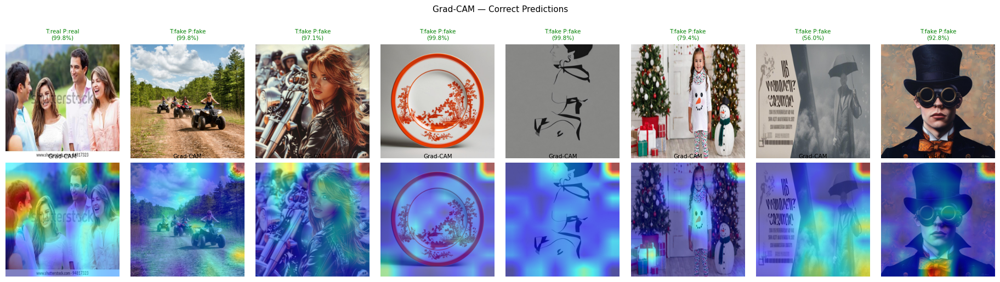


=== Grad-CAM: Misclassified Samples ===


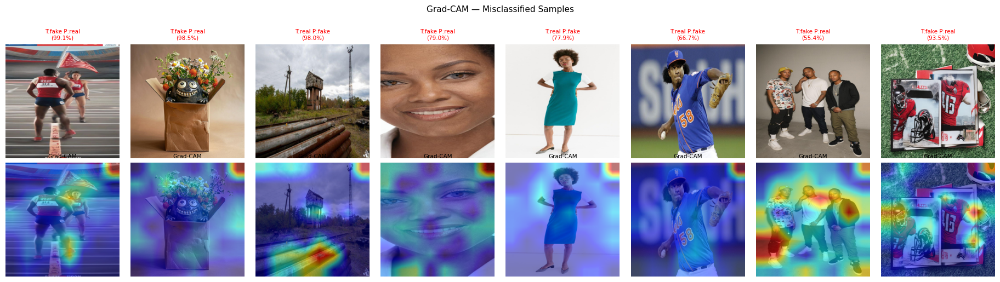

In [ ]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

# Temporarily enable gradients for Grad-CAM
for p in model.parameters():
    p.requires_grad = True

target_layer = [model.blocks[-1]]
cam = GradCAM(model=model, target_layers=target_layer)

def gradcam_grid(df_subset, title, n_show=8):
    """Show original + Grad-CAM overlay for a subset of the dataframe."""
    sub = df_subset.head(n_show)
    n   = len(sub)
    if n == 0:
        print(f'No samples for: {title}')
        return

    fig, axes = plt.subplots(2, n, figsize=(2.3 * n, 5))
    if n == 1:
        axes = axes.reshape(2, 1)

    for i, (_, row) in enumerate(sub.iterrows()):
        img_pil   = Image.open(row['path']).convert('RGB')
        tensor    = test_transforms(img_pil).unsqueeze(0).to(DEVICE)
        grayscale = cam(input_tensor=tensor)[0]
        img_np    = np.array(img_pil.resize((SIZE, SIZE))).astype(np.float32) / 255.0
        cam_img   = show_cam_on_image(img_np, grayscale, use_rgb=True)

        true_lbl = CLASS_NAMES[int(row['label'])]
        pred_lbl = CLASS_NAMES[int(row['pred'])]
        conf     = row['prob'] if row['pred'] == 1 else 1 - row['prob']
        color    = 'green' if row['pred'] == row['label'] else 'red'

        axes[0, i].imshow(img_np)
        axes[0, i].set_title(f'T:{true_lbl} P:{pred_lbl}\n({conf:.1%})',
                              fontsize=7.5, color=color)
        axes[0, i].axis('off')
        axes[1, i].imshow(cam_img)
        axes[1, i].set_title('Grad-CAM', fontsize=7.5)
        axes[1, i].axis('off')

    plt.suptitle(title, fontsize=11, y=1.02)
    plt.tight_layout()
    plt.show()

print('=== Grad-CAM: Correctly Classified Samples ===')
correct_df = results_df[results_df['pred'] == results_df['label']].sample(
    n=min(8, (results_df['pred'] == results_df['label']).sum()), random_state=42)
gradcam_grid(correct_df, 'Grad-CAM — Correct Predictions', n_show=8)

print()
print('=== Grad-CAM: Misclassified Samples ===')
gradcam_grid(wrong_df.sample(n=min(8, len(wrong_df)), random_state=42),
             'Grad-CAM — Misclassified Samples', n_show=8)

=== Grad-CAM: Misclassifications Per Generator ===


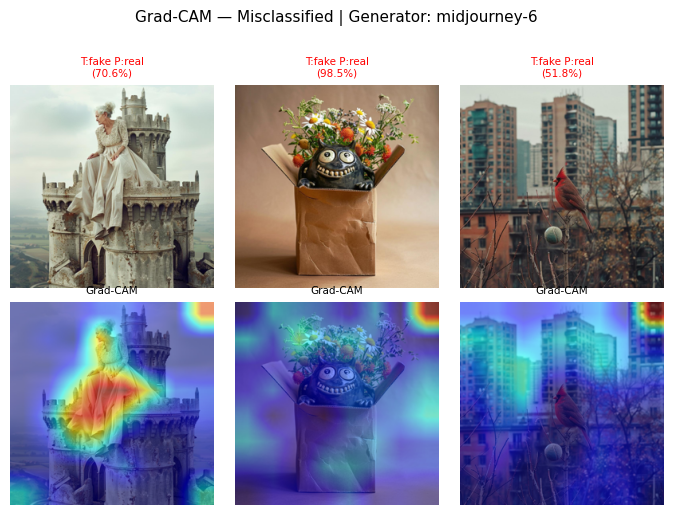

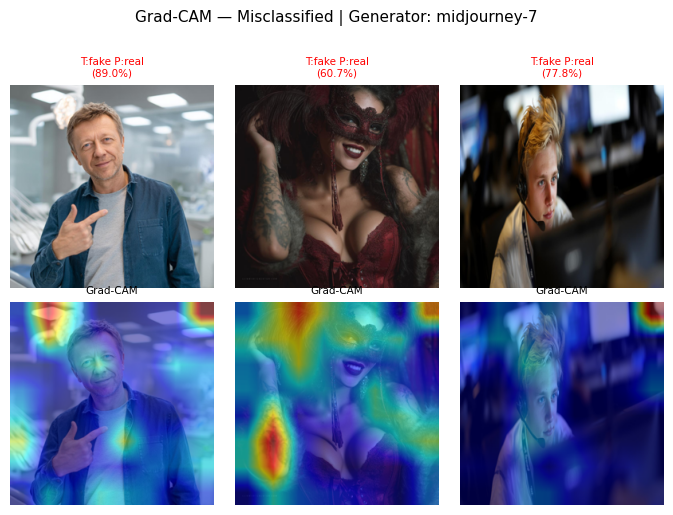

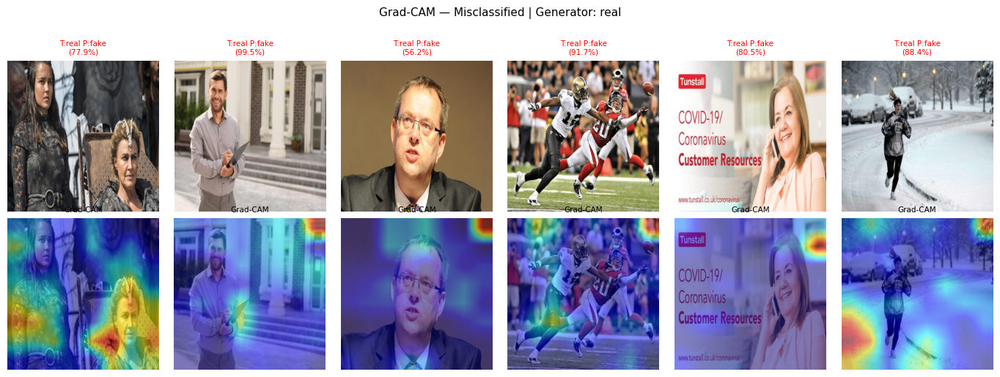

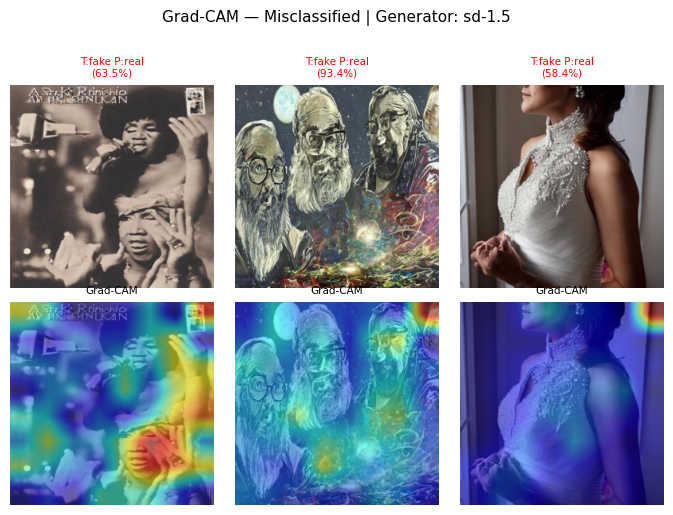

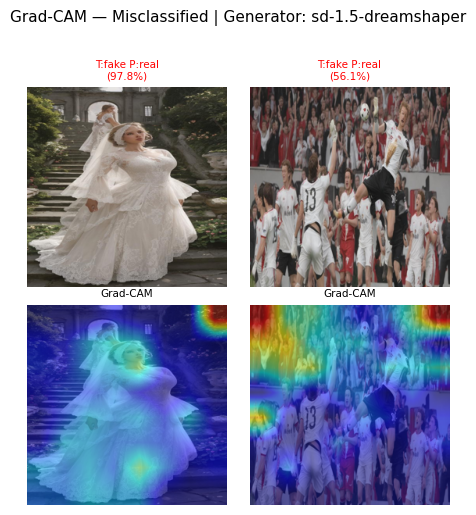

...

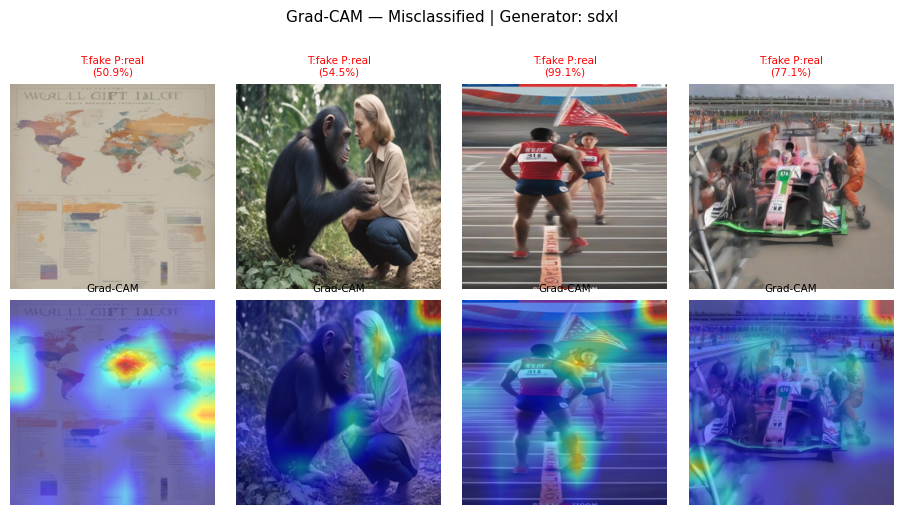

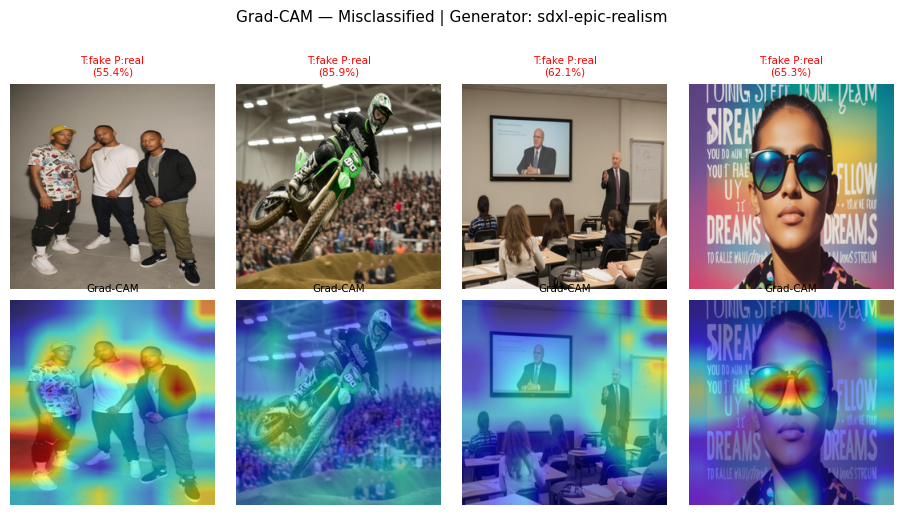

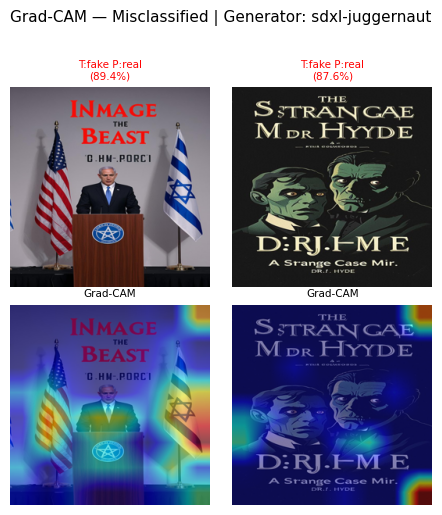

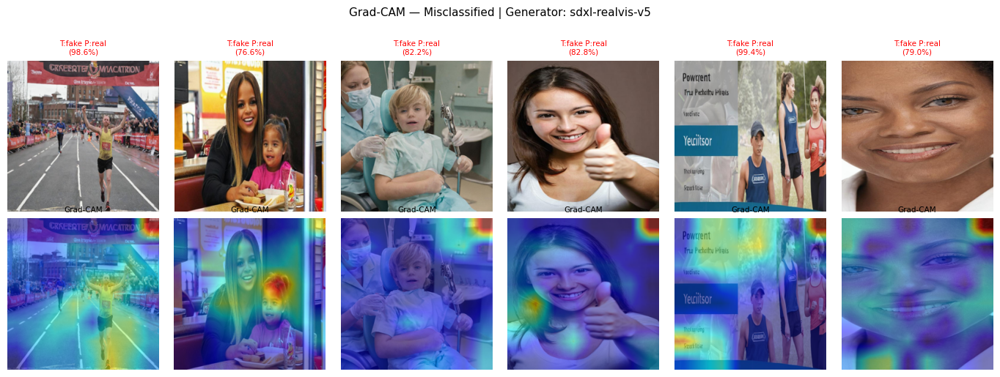

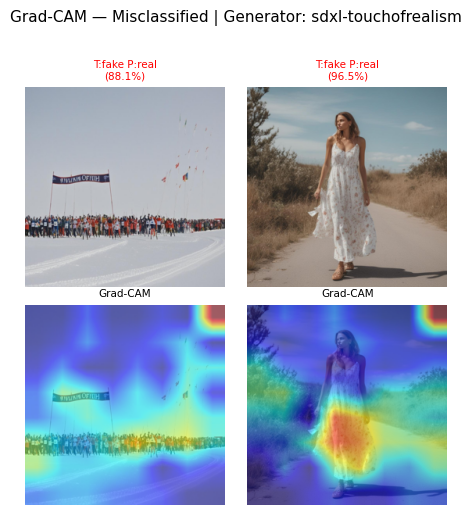

In [ ]:
# Grad-CAM per generator
print('=== Grad-CAM: Misclassifications Per Generator ===')
for gen in sorted(wrong_df['generator'].unique()):
    sub = wrong_df[wrong_df['generator'] == gen]
    gradcam_grid(sub.head(6), f'Grad-CAM — Misclassified | Generator: {gen}', n_show=6)

# Re-freeze after Grad-CAM
for p in model.parameters():
    p.requires_grad = False

## 14. Evaluation on New Unseen Dataset

This dataset contains images from **generator models not seen during training**. We evaluate the model's generalisation ability on this out-of-distribution data.

In [ ]:
# ── Extract new dataset ───────────────────────────────────────────────────────
NEW_REAL ="/content/drive/MyDrive/EfficientModel/ood_test/real"
NEW_FAKE ="/content/drive/MyDrive/EfficientModel/ood_test/fake"

print(f'New dataset images: {len(os.listdir(NEW_REAL)):,}')

New dataset images: 1,177


In [ ]:
# ── Load new dataset from folder structure (no CSV) ───────────────────────────

REAL_FOLDER = NEW_REAL
FAKE_FOLDER = NEW_FAKE
print(f'Real folder : {REAL_FOLDER}')
print(f'Fake folder : {FAKE_FOLDER}')

# ── Build dataframe from folder contents ─────────────────────────────────────
IMG_EXTS = {'.jpg', '.jpeg', '.png', '.webp', '.bmp'}
def collect_images(folder_path, label, generator_name):

  real_num=0
  rows = []
  for fname in os.listdir(folder_path):
    if label ==0:
      real_num +=1
      if real_num ==451:
        real_num=0
        return rows
    if os.path.splitext(fname)[1].lower() in IMG_EXTS:
        rows.append({
            'resolved_path' : os.path.join(folder_path, fname),
            'filename'      : fname,
            'binary_label'  : label,
            'model'         : generator_name,
        })
  return rows

real_path = NEW_REAL
fake_path = NEW_FAKE

rows = collect_images(fake_path, label=1, generator_name="fake")
rows  += collect_images(real_path, label=0, generator_name='real')

df_new = pd.DataFrame(rows).reset_index(drop=True)

# Verify all files exist
exists_mask = df_new['resolved_path'].apply(os.path.exists)
if (~exists_mask).sum() > 0:
    print(f'Warning: {(~exists_mask).sum()} missing files dropped.')
df_new = df_new[exists_mask].reset_index(drop=True)

has_model_col_new = True   # we built the column ourselves

print(f'\nNew dataset : {len(df_new):,} images')
print(f'Real        : {(df_new.binary_label==0).sum():,}')
print(f'Fake        : {(df_new.binary_label==1).sum():,}')
print(f'Generator   : {df_new["model"].unique().tolist()}')

Real folder : /content/drive/MyDrive/EfficientModel/ood_test/real
Fake folder : /content/drive/MyDrive/EfficientModel/ood_test/fake

New dataset : 1,350 images
Real        : 450
Fake        : 900
Generator   : ['fake', 'real']


In [ ]:
new_loader = make_loader(df_new, test_transforms,
                         has_model_col=has_model_col_new,
                         batch_size=CFG['batch_size'],
                         num_workers=CFG['num_workers'])

new_preds, new_labels, new_probs, new_gens, new_paths = run_inference(
    new_loader, model, DEVICE)

print(f'Inference done on {len(new_preds):,} new images.')

Inference:   0%|          | 0/43 [00:00<?, ?it/s]

Inference done on 1,350 new images.


### 14a. New Dataset — Overall Metrics

In [ ]:
new_acc    = np.mean(new_preds == new_labels)
new_recall = recall_score(new_labels, new_preds, average='macro')
new_f1     = f1_score(new_labels, new_preds, average='macro')
new_prec   = precision_score(new_labels, new_preds, average='macro')
try:
    new_auc = roc_auc_score(new_labels, new_probs)
except ValueError:
    new_auc = float('nan')

print('=' * 50)
print('  NEW UNSEEN DATASET RESULTS')
print('=' * 50)
print(f'  Accuracy   : {new_acc:.4f}  ({new_acc*100:.2f}%)')
print(f'  ROC-AUC    : {new_auc:.4f}')
print(f'  Precision  : {new_prec:.4f}')
print(f'  Recall     : {new_recall:.4f}')
print(f'  F1-Score   : {new_f1:.4f}')
print('=' * 50)
print()
print(classification_report(new_labels, new_preds, target_names=CLASS_NAMES, digits=4))

  NEW UNSEEN DATASET RESULTS
  Accuracy   : 0.4822  (48.22%)
  ROC-AUC    : 0.4800
  Precision  : 0.4867
  Recall     : 0.4850
  F1-Score   : 0.4698

              precision    recall  f1-score   support

        real     0.3203    0.4933    0.3885       450
        fake     0.6530    0.4767    0.5511       900

    accuracy                         0.4822      1350
   macro avg     0.4867    0.4850    0.4698      1350
weighted avg     0.5421    0.4822    0.4969      1350



### 14b. New Dataset — Confusion Matrix & ROC Curve

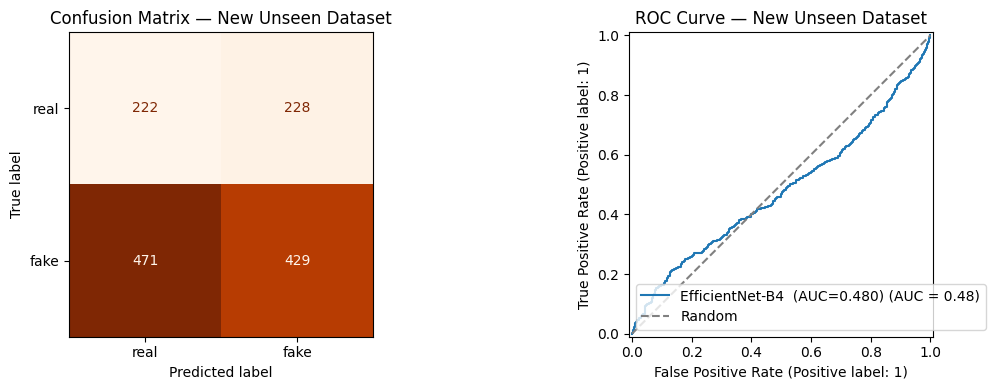

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

cm_new = confusion_matrix(new_labels, new_preds)
ConfusionMatrixDisplay(cm_new, display_labels=CLASS_NAMES).plot(
    ax=ax1, cmap='Oranges', colorbar=False
)
ax1.set_title('Confusion Matrix — New Unseen Dataset')

try:
    RocCurveDisplay.from_predictions(
        new_labels, new_probs,
        name=f'EfficientNet-B4  (AUC={new_auc:.3f})',
        ax=ax2
    )
    ax2.plot([0, 1], [0, 1], '--', color='gray', label='Random')
    ax2.set_title('ROC Curve — New Unseen Dataset')
    ax2.legend()
except Exception as e:
    ax2.text(0.5, 0.5, str(e), ha='center')

plt.tight_layout()
plt.show()

### 14c. New Dataset — Per-Generator Metrics

In [ ]:
new_results_df = pd.DataFrame({
    'pred'      : new_preds,
    'label'     : new_labels,
    'prob'      : new_probs,
    'generator' : new_gens,
    'path'      : new_paths,
})

if has_model_col_new and new_results_df['generator'].nunique() > 1:
    new_gen_stats = []
    for gen in sorted(new_results_df['generator'].unique()):
        sub   = new_results_df[new_results_df['generator'] == gen]
        y_t, y_p, y_pr = sub['label'].values, sub['pred'].values, sub['prob'].values
        try:
            g_auc = roc_auc_score(y_t, y_pr)
        except ValueError:
            g_auc = float('nan')
        n_wrong = (y_p != y_t).sum()
        new_gen_stats.append({
            'Generator' : gen,
            'N'         : len(sub),
            'N_Wrong'   : n_wrong,
            'Error_%'   : round(100 * n_wrong / len(sub), 2),
            'Accuracy'  : round(np.mean(y_p == y_t), 4),
            'ROC-AUC'   : round(g_auc, 4),
            'Recall'    : round(recall_score(y_t, y_p, average='macro', zero_division=0), 4),
            'F1'        : round(f1_score(y_t, y_p, average='macro', zero_division=0), 4),
        })
    display(pd.DataFrame(new_gen_stats).set_index('Generator'))
else:
    print('Single generator or no model column — per-generator table skipped.')

,N,N_Wrong,Error_%,Accuracy,ROC-AUC,Recall,F1
Generator,,,,,,,
fake,900,471,52.33,0.4767,NaN,0.2383,0.3228
real,450,228,50.67,0.4933,NaN,0.2467,0.3304


### 14d. New Dataset — Error Analysis (Misclassified Images)

Misclassified on new dataset: 699 / 1,350  (51.78%)


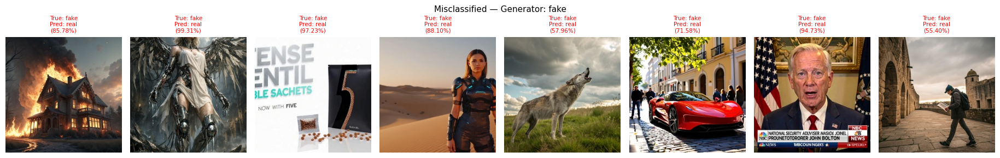

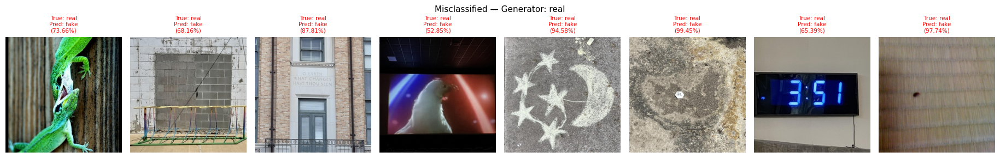

In [ ]:
new_wrong_df = new_results_df[new_results_df['pred'] != new_results_df['label']].copy()
print(f'Misclassified on new dataset: {len(new_wrong_df):,} / {len(new_results_df):,}  '
      f'({100*len(new_wrong_df)/len(new_results_df):.2f}%)')

if has_model_col_new:
    for gen in sorted(new_wrong_df['generator'].unique()):
        show_errors(new_wrong_df[new_wrong_df['generator'] == gen],
                    generator=gen, n_show=8)
else:
    show_errors(new_wrong_df, generator='unknown', n_show=8)

### 14e. New Dataset — Grad-CAM

=== Grad-CAM: New Dataset — Correct Predictions ===


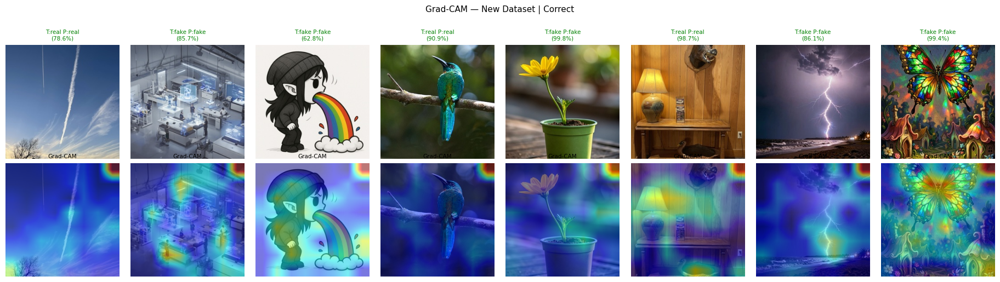


=== Grad-CAM: New Dataset — Misclassified ===


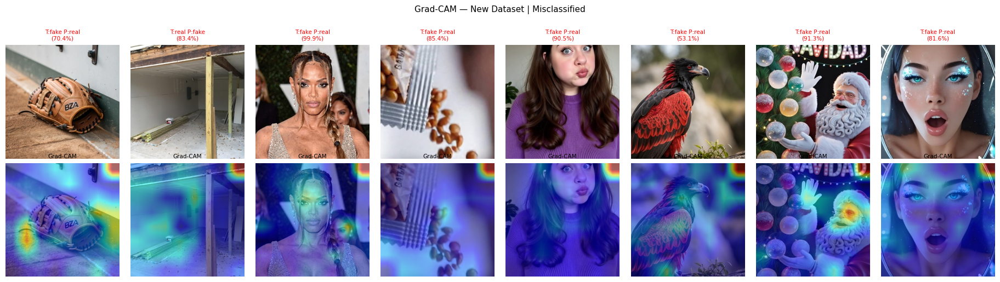

In [ ]:
for p in model.parameters():
    p.requires_grad = True

print('=== Grad-CAM: New Dataset — Correct Predictions ===')
new_correct = new_results_df[new_results_df['pred'] == new_results_df['label']].sample(
    n=min(8, (new_results_df['pred'] == new_results_df['label']).sum()), random_state=42)
gradcam_grid(new_correct, 'Grad-CAM — New Dataset | Correct', n_show=8)

print()
print('=== Grad-CAM: New Dataset — Misclassified ===')
if len(new_wrong_df) > 0:
    gradcam_grid(new_wrong_df.sample(n=min(8, len(new_wrong_df)), random_state=42),
                 'Grad-CAM — New Dataset | Misclassified', n_show=8)

for p in model.parameters():
    p.requires_grad = False

## 15. Side-by-Side Summary: Test Set vs New Dataset

,Test Set,New Dataset
Metric,,
Accuracy,0.8311,0.4822
ROC-AUC,0.9229,0.4800
Macro Precision,0.8407,0.4867
Macro Recall,0.8783,0.4850
Macro F1,0.8406,0.4698


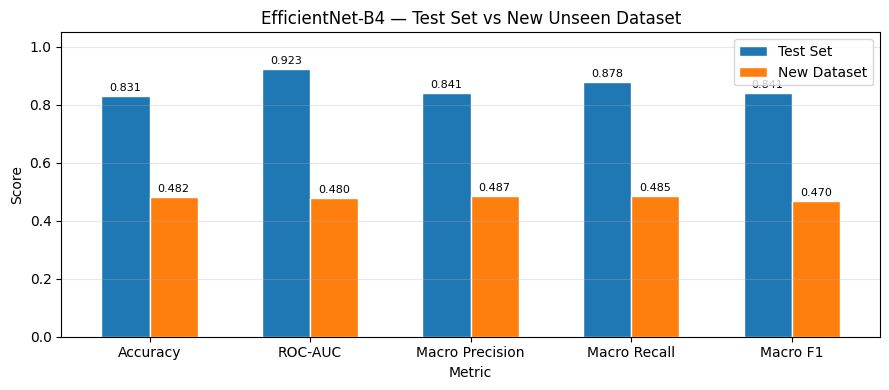

In [ ]:
summary = pd.DataFrame({
    'Metric'         : ['Accuracy', 'ROC-AUC', 'Macro Precision', 'Macro Recall', 'Macro F1'],
    'Test Set'       : [acc, auc, prec, recall, f1],
    'New Dataset'    : [new_acc, new_auc, new_prec, new_recall, new_f1],
}).set_index('Metric').round(4)

display(summary)

# Bar chart
ax = summary.plot(kind='bar', figsize=(9, 4), rot=0, edgecolor='white', width=0.6)
ax.set_ylim(0, 1.05)
ax.set_title('EfficientNet-B4 — Test Set vs New Unseen Dataset', fontsize=12)
ax.set_ylabel('Score')
ax.legend()
ax.grid(axis='y', alpha=0.3)
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', fontsize=8, padding=2)
plt.tight_layout()
plt.show()

model.safetensors:   0%|          | 0.00/77.9M [00:00<?, ?B/s]

Model  : efficientnet_b4  (ImageNet weights, NO fine-tuning)
Params : 17,552,202  |  Trainable: 0  (all frozen)

── Original Test Set ──


Inference:   0%|          | 0/29 [00:00<?, ?it/s]

  Accuracy   : 0.5011  (50.11%)
  ROC-AUC    : 0.5221
  Precision  : 0.5180
  Recall     : 0.5200
  F1-Score   : 0.4942

              precision    recall  f1-score   support

        real     0.3495    0.5767    0.4352       300
        fake     0.6864    0.4633    0.5532       600

    accuracy                         0.5011       900
   macro avg     0.5180    0.5200    0.4942       900
weighted avg     0.5741    0.5011    0.5139       900



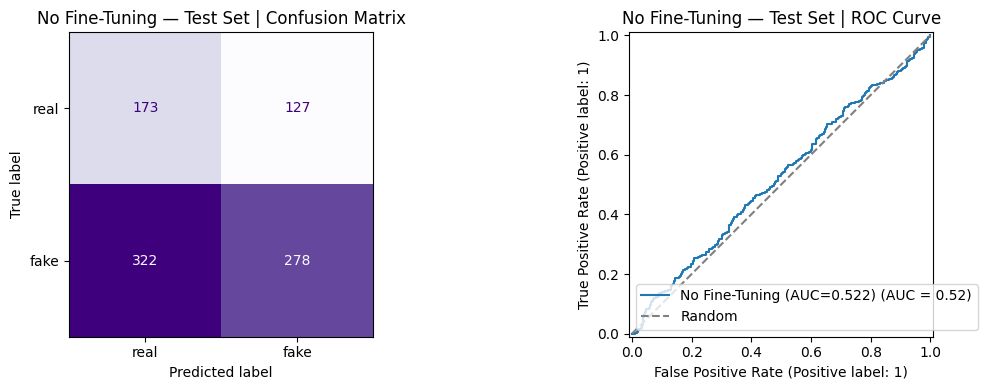

In [ ]:
# ── Load vanilla ImageNet model (no fine-tuning) ──────────────────────────────
model_noft = timm.create_model(
    CFG['model_name'],
    pretrained=True,
    num_classes=CFG['num_classes']
).to(DEVICE)

for p in model_noft.parameters():
    p.requires_grad = False
model_noft.eval()

total = sum(p.numel() for p in model_noft.parameters())
print(f'Model  : {CFG["model_name"]}  (ImageNet weights, NO fine-tuning)')
print(f'Params : {total:,}  |  Trainable: 0  (all frozen)')

# ── Evaluate on original test set ─────────────────────────────────────────────
print('\n── Original Test Set ──')
noft_preds, noft_labels, noft_probs, _, _ = run_inference(test_loader, model_noft, DEVICE)

noft_acc    = np.mean(noft_preds == noft_labels)
noft_recall = recall_score(noft_labels, noft_preds, average='macro')
noft_f1     = f1_score(noft_labels, noft_preds, average='macro')
noft_prec   = precision_score(noft_labels, noft_preds, average='macro')
try:
    noft_auc = roc_auc_score(noft_labels, noft_probs)
except ValueError:
    noft_auc = float('nan')

print(f'  Accuracy   : {noft_acc:.4f}  ({noft_acc*100:.2f}%)')
print(f'  ROC-AUC    : {noft_auc:.4f}')
print(f'  Precision  : {noft_prec:.4f}')
print(f'  Recall     : {noft_recall:.4f}')
print(f'  F1-Score   : {noft_f1:.4f}')
print()
print(classification_report(noft_labels, noft_preds, target_names=CLASS_NAMES, digits=4))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
cm_noft = confusion_matrix(noft_labels, noft_preds)
ConfusionMatrixDisplay(cm_noft, display_labels=CLASS_NAMES).plot(ax=ax1, cmap='Purples', colorbar=False)
ax1.set_title('No Fine-Tuning — Test Set | Confusion Matrix')
RocCurveDisplay.from_predictions(noft_labels, noft_probs,
    name=f'No Fine-Tuning (AUC={noft_auc:.3f})', ax=ax2)
ax2.plot([0,1],[0,1],'--',color='gray',label='Random'); ax2.legend()
ax2.set_title('No Fine-Tuning — Test Set | ROC Curve')
plt.tight_layout(); plt.show()

── New Unseen Dataset ──


Inference:   0%|          | 0/43 [00:00<?, ?it/s]

  Accuracy   : 0.5015  (50.15%)
  ROC-AUC    : 0.5031
  Precision  : 0.4906
  Recall     : 0.4894
  F1-Score   : 0.4809

              precision    recall  f1-score   support

        real     0.3233    0.4533    0.3774       450
        fake     0.6579    0.5256    0.5843       900

    accuracy                         0.5015      1350
   macro avg     0.4906    0.4894    0.4809      1350
weighted avg     0.5463    0.5015    0.5154      1350



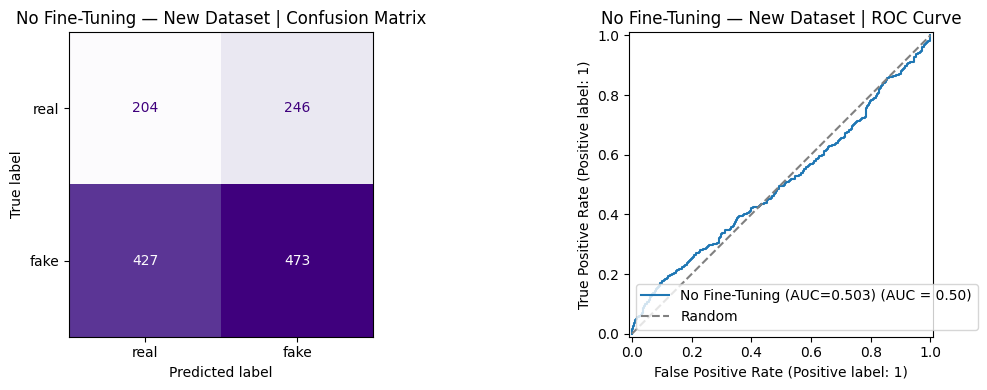


── Summary: Fine-Tuned vs No Fine-Tuning ──


,FT — Test Set,No-FT — Test Set,FT — New Dataset,No-FT — New Dataset
Metric,,,,
Accuracy,0.8311,0.5011,0.4822,0.5015
ROC-AUC,0.9229,0.5221,0.4800,0.5031
Precision,0.8407,0.5180,0.4867,0.4906
Recall,0.8783,0.5200,0.4850,0.4894
F1,0.8406,0.4942,0.4698,0.4809


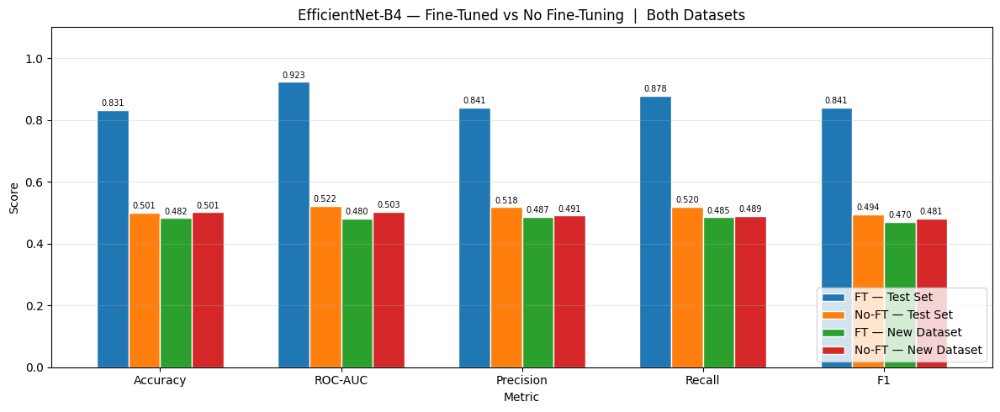

In [ ]:
# ── Evaluate on new unseen dataset (no fine-tuning) ───────────────────────────
print('── New Unseen Dataset ──')
noft_new_preds, noft_new_labels, noft_new_probs, _, _ = run_inference(
    new_loader, model_noft, DEVICE)

noft_new_acc    = np.mean(noft_new_preds == noft_new_labels)
noft_new_recall = recall_score(noft_new_labels, noft_new_preds, average='macro')
noft_new_f1     = f1_score(noft_new_labels, noft_new_preds, average='macro')
noft_new_prec   = precision_score(noft_new_labels, noft_new_preds, average='macro')
try:
    noft_new_auc = roc_auc_score(noft_new_labels, noft_new_probs)
except ValueError:
    noft_new_auc = float('nan')

print(f'  Accuracy   : {noft_new_acc:.4f}  ({noft_new_acc*100:.2f}%)')
print(f'  ROC-AUC    : {noft_new_auc:.4f}')
print(f'  Precision  : {noft_new_prec:.4f}')
print(f'  Recall     : {noft_new_recall:.4f}')
print(f'  F1-Score   : {noft_new_f1:.4f}')
print()
print(classification_report(noft_new_labels, noft_new_preds, target_names=CLASS_NAMES, digits=4))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
cm_noft_new = confusion_matrix(noft_new_labels, noft_new_preds)
ConfusionMatrixDisplay(cm_noft_new, display_labels=CLASS_NAMES).plot(ax=ax1, cmap='Purples', colorbar=False)
ax1.set_title('No Fine-Tuning — New Dataset | Confusion Matrix')
try:
    RocCurveDisplay.from_predictions(noft_new_labels, noft_new_probs,
        name=f'No Fine-Tuning (AUC={noft_new_auc:.3f})', ax=ax2)
    ax2.plot([0,1],[0,1],'--',color='gray',label='Random'); ax2.legend()
except Exception as e:
    ax2.text(0.5,0.5,str(e),ha='center')
ax2.set_title('No Fine-Tuning — New Dataset | ROC Curve')
plt.tight_layout(); plt.show()

# ── Full comparison table: Fine-Tuned vs No Fine-Tuning ───────────────────────
print('\n── Summary: Fine-Tuned vs No Fine-Tuning ──')
cmp = pd.DataFrame({
    'Metric'              : ['Accuracy','ROC-AUC','Precision','Recall','F1'],
    'FT — Test Set'       : [acc,     auc,     prec,     recall,     f1],
    'No-FT — Test Set'    : [noft_acc, noft_auc, noft_prec, noft_recall, noft_f1],
    'FT — New Dataset'    : [new_acc,  new_auc,  new_prec,  new_recall,  new_f1],
    'No-FT — New Dataset' : [noft_new_acc, noft_new_auc, noft_new_prec, noft_new_recall, noft_new_f1],
}).set_index('Metric').round(4)
display(cmp)

ax = cmp.plot(kind='bar', figsize=(12, 5), rot=0, edgecolor='white', width=0.7)
ax.set_ylim(0, 1.1)
ax.set_title('EfficientNet-B4 — Fine-Tuned vs No Fine-Tuning  |  Both Datasets', fontsize=12)
ax.set_ylabel('Score')
ax.legend(loc='lower right')
ax.grid(axis='y', alpha=0.3)
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', fontsize=7, padding=2)
plt.tight_layout()
plt.show()

In [ ]:
# ── Same per-generator binary evaluation for NO fine-tuning model ─────────────

noft_preds_arr, noft_labels_arr, noft_probs_arr, noft_gens_arr, noft_paths_arr = \
    run_inference(test_loader, model_noft, DEVICE)

noft_results_df = pd.DataFrame({
    'pred'      : noft_preds_arr,
    'label'     : noft_labels_arr,
    'prob'      : noft_probs_arr,
    'generator' : noft_gens_arr,
    'path'      : noft_paths_arr,
})
noft_results_df['generator_group'] = noft_results_df['generator'].apply(normalise_gen)

noft_real_pool = noft_results_df[noft_results_df['label'] == 0].copy()
noft_fake_df   = noft_results_df[
    (noft_results_df['label'] == 1) & (noft_results_df['generator_group'] != '__real__')
].copy()

noft_gen_stats = []
for gen in sorted(noft_fake_df['generator_group'].unique()):
    sub     = noft_fake_df[noft_fake_df['generator_group'] == gen]
    n_fake  = len(sub)
    n_wrong = (sub['pred'].values != 1).sum()

    combined = pd.concat([sub, noft_real_pool])
    yc_true  = combined['label'].values
    yc_pred  = combined['pred'].values
    yc_prob  = combined['prob'].values

    acc  = np.mean(sub['pred'].values == 1)
    auc  = roc_auc_score(yc_true, yc_prob)
    rec  = recall_score(yc_true, yc_pred,    average='macro', zero_division=0)
    f1   = f1_score(yc_true, yc_pred,        average='macro', zero_division=0)
    prec = precision_score(yc_true, yc_pred, average='macro', zero_division=0)

    noft_gen_stats.append({
        'Generator'        : gen,
        'N_fake'           : n_fake,
        'N_real'           : len(noft_real_pool),
        'N_wrong (missed)' : n_wrong,
        'Detection_Rate%'  : round(100 * acc,  2),
        'Error_%'          : round(100 * n_wrong / n_fake, 2),
        'ROC-AUC'          : round(auc,  4),
        'Recall (macro)'   : round(rec,  4),
        'F1 (macro)'       : round(f1,   4),
        'Precision (macro)': round(prec, 4),
    })

noft_stats_df = pd.DataFrame(noft_gen_stats).set_index('Generator')

print('── No Fine-Tuning: Per-Generator Binary Evaluation ──\n')
display(noft_stats_df)

# ── Side-by-side comparison ───────────────────────────────────────────────────
print('\n── Fine-Tuned vs No Fine-Tuning — Detection_Rate% per Generator ──\n')
compare_df = pd.DataFrame({
    'FT Detection_Rate%'    : stats_df['Detection_Rate%'],
    'No-FT Detection_Rate%' : noft_stats_df['Detection_Rate%'],
    'FT ROC-AUC'            : stats_df['ROC-AUC'],
    'No-FT ROC-AUC'         : noft_stats_df['ROC-AUC'],
    'FT F1'                 : stats_df['F1 (macro)'],
    'No-FT F1'              : noft_stats_df['F1 (macro)'],
})
display(compare_df)

Inference:   0%|          | 0/29 [00:00<?, ?it/s]

── No Fine-Tuning: Per-Generator Binary Evaluation ──



,N_fake,N_real,N_wrong (missed),Detection_Rate%,Error_%,ROC-AUC,Recall (macro),F1 (macro),Precision (macro)
Generator,,,,,,,,,
midjourney,304,300,150,50.66,49.34,0.5461,0.5416,0.5409,0.5418
stable_diffusion,296,300,172,41.89,58.11,0.4974,0.4978,0.4949,0.4977



── Fine-Tuned vs No Fine-Tuning — Detection_Rate% per Generator ──



,FT Detection_Rate%,No-FT Detection_Rate%,FT ROC-AUC,No-FT ROC-AUC,FT F1,No-FT F1
Generator,,,,,,
midjourney,98.03,50.66,0.9788,0.5461,0.9151,0.5409
stable_diffusion,83.11,41.89,0.9229,0.4974,0.8406,0.4949
